# 39 · CIFAR-100 phase by label level

Does the same orientation signal distinguish related fine categories and retrieve other fine classes in the same superclass? Phase and magnitude use a shared offset selected by aligned ZNCC. Compare them with aligned ZNCC and standard-preprocessing ResNet-50 V1. No score or model is fitted.

**Result.** On transformed queries, phase increased coarse top-1 by 2.94 percentage points (95% CI 0.36 to 5.60) and fine top-1 by 2.68 points (−0.49 to 5.65). The paired comparison of pair-accuracy gains leaves the difference between levels unresolved. Frozen ResNet-50 led top-1 at both levels.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'observables').is_dir())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
R = ROOT/'results'/'stage12'
import json
from observables.stage6 import CONDITIONS
from observables.stage12 import METHODS
manifest = json.loads((R/'manifest.json').read_text())
encoder = json.loads((R/'encoder_224.json').read_text())
old = json.loads((ROOT/'results'/'stage11'/'encoder_224.json').read_text())
assert encoder['checkpoint_sha256'] == old['checkpoint_sha256']
assert encoder['test_sha256'] == manifest['test_sha256']
assert encoder['resize'] == old['resize'] == [256]
assert encoder['size'] == old['size'] == 224
summary = pd.read_csv(R/'summary.csv')
effects = pd.read_csv(R/'phase_contrasts.csv')
metrics = ['top1','ap','pair_accuracy']
labels = ['Category top-1','Mean average precision','Within-query pair accuracy']


## 1. Clean and transformed retrieval

Top-1 chance is 14.29% for fine and 15.79% for coarse retrieval. Pair accuracy compares a positive with a negative drawn from the eligible candidate set and has chance 50% in both tasks.

In [3]:
table = summary.pivot(index='method', columns=['split','task'], values=metrics)
display((100*table.reindex(METHODS)).round(2))
display((100*effects.set_index(['split','task','metric'])[['delta','low95','high95']]).round(2))


top1                               ap                     \
split         clean        transformed         clean        transformed   
task         coarse   fine      coarse   fine coarse   fine      coarse   
method                                                                    
magnitude     21.04  17.92       18.80  16.15  25.18  39.82       24.61   
phase         25.00  19.79       21.74  18.83  25.86  42.30       25.23   
aligned ZNCC  23.33  21.46       23.18  20.26  27.68  43.97       27.64   
encoder 224   56.04  32.92       41.09  28.67  47.95  53.35       40.05   

                    pair_accuracy                            
split                       clean        transformed         
task           fine        coarse   fine      coarse   fine  
method                                                       
magnitude     38.64         52.48  52.40       51.56  51.39  
phase         40.89         52.05  54.83       51.85  53.16  
aligned ZNCC  43.17         55.12  57.29       55.08  56.73  
encoder 224   49.45         73.81  67.12       67.40  62.76

delta  low95  high95
split       task              metric                             
clean       fine              top1            1.88  -1.25    5.00
            coarse            top1            3.96  -2.08    9.79
            fine              ap              2.48   0.33    4.95
            coarse            ap              0.68  -0.93    2.40
            fine              pair_accuracy   2.43  -0.31    5.35
            coarse            pair_accuracy  -0.44  -2.65    1.97
            coarse minus fine pair_accuracy  -2.87  -7.57    1.79
transformed fine              top1            2.68  -0.49    5.65
            coarse            top1            2.94   0.36    5.60
            fine              ap              2.25  -0.05    4.65
            coarse            ap              0.62  -0.37    1.63
            fine              pair_accuracy   1.77  -0.75    4.56
            coarse            pair_accuracy   0.29  -1.31    1.95
            coarse minus fine pair_accuracy  -1.48  -5.60    2.52

## 2. Paired phase effects

Intervals are pointwise 95% gallery bootstraps. The secondary coarse-minus-fine interaction uses the paired difference in within-query pair accuracy. The two tasks use different negatives, so this interaction applies to these two retrieval designs.

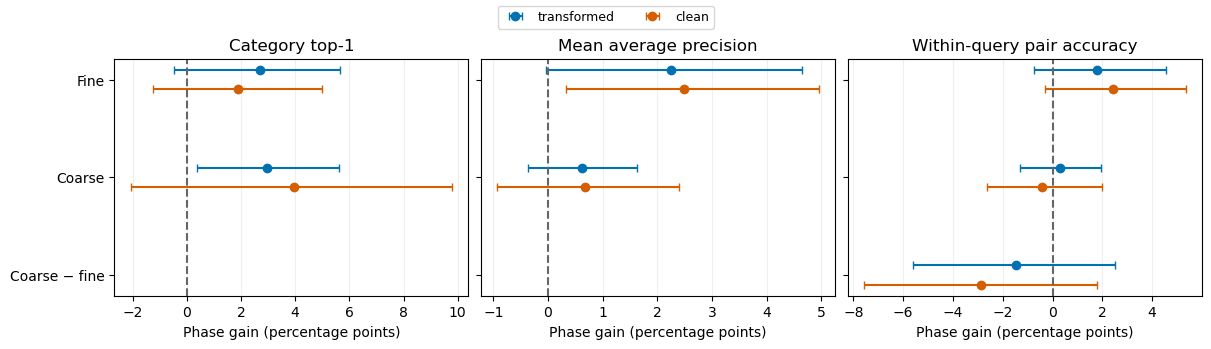

In [5]:
fig, axes = plt.subplots(1,3,figsize=(12,3.4),sharey=True,layout='constrained')
levels = ['fine','coarse','coarse minus fine']
for ax, metric, label in zip(axes, metrics, labels):
    for split, offset, color in [('transformed',-.10,'#0072b2'),('clean',.10,'#d55e00')]:
        rows = effects.query('metric == @metric and split == @split').set_index('task').reindex(levels).dropna()
        idx = [levels.index(level) for level in rows.index]
        d, lo, hi = (100*rows[c].to_numpy() for c in ['delta','low95','high95'])
        ax.errorbar(d,np.array(idx)+offset,xerr=[d-lo,hi-d],fmt='o',color=color,capsize=3,label=split)
    ax.axvline(0,ls='--',color='0.4')
    ax.set(title=label, xlabel='Phase gain (percentage points)', yticks=np.arange(3),
           yticklabels=['Fine', 'Coarse', 'Coarse − fine'])
    ax.grid(axis='x',alpha=.2)
axes[0].invert_yaxis()
handles, names = axes[2].get_legend_handles_labels()
fig.legend(handles, names, loc='outside upper center', ncols=2, fontsize=9)
fig.savefig(R/'39_phase_contrasts.png',dpi=165)
plt.show()


## 3. Phase gain by perturbation

These condition-specific point estimates are descriptive. The same original image contributes all views, and the aggregate bootstrap retains those dependencies by resampling whole galleries.

In [7]:
by = pd.read_csv(R/'condition_summary.csv').pivot(index=['condition','task'],columns='method',values=metrics)
delta = {metric:100*(by[(metric,'phase')]-by[(metric,'magnitude')]) for metric in metrics}
display(pd.DataFrame(delta).reindex(pd.MultiIndex.from_product([CONDITIONS,['fine','coarse']],
                                                            names=['condition','task'])).round(2))


top1    ap  pair_accuracy
condition     task                             
clean         fine    1.87  2.48           2.43
              coarse  3.96  0.68          -0.44
shift         fine    2.71  2.44           1.81
              coarse  2.71  0.77           0.12
gain          fine    2.29  2.39           2.71
              coarse  3.33  0.42          -0.08
noise         fine    2.71  2.10           1.53
              coarse  3.33  0.66           0.64
blur          fine    3.12  2.71           2.43
              coarse  1.25  0.95           0.71
rotation      fine    6.46  4.56           2.47
              coarse  1.04 -0.37           0.27
crop          fine    3.33  2.31           0.59
              coarse  5.00  0.91           0.07
occlusion     fine    0.00  0.25           0.00
              coarse  5.62  0.92          -0.11
shift + noise fine    0.83  1.20           2.64
              coarse  1.25  0.71           0.72